# Chapter 4. Choosing the markets

**Question.** Which markets should the sleeve trade, and can that choice be
made without fooling ourselves?

**Covers** (original notebooks 08, 09, 11, 16, 22 and v2/01, v2/02, v2/04,
plus the nested selection tests):
1. from 7 markets to 19: breadth;
2. trimming 19 to 15 by leave-one-out contribution ("Sleeve A");
3. every possible 15 of the 19, exhaustively;
4. what the broker can actually trade;
5. a wider pool of 30 and a large random search;
6. **the nested test that showed aggressive selection is self-deception**;
7. the selection premium inside the final universe's headline.

**Configuration:** the bare engine (no layers), gross, so that the choice
of markets cannot depend on a layer that might later be dropped. Weekly,
as the selection work was done before monthly was chosen. Sharpe after the
risk-free rate, out of sample from 2008-09-04, unless a cell says otherwise.

In [1]:
from itertools import combinations
from _setup import *
from ctadata import LEAN_7, EXPANDED_19, SLEEVE_A_15, symbols_of, asset_class

E19 = sorted(symbols_of(EXPANDED_19))
A15 = sorted(symbols_of(SLEEVE_A_15))
_cache = {}


def ret(syms, kw=DEFAULT_PARAMS):
    """Bare-engine daily returns for a set of markets, memoised."""
    k = (tuple(sorted(syms)), tuple(sorted(kw.items())))
    if k not in _cache:
        _cache[k] = returns(build_trend_nav_fast(df, symbols=list(k[0]), **kw)[0])
    return _cache[k]


def sh(r):
    return sharpe(oos(r), RF)

## 1. From 7 markets to 19

Grinold's fundamental law says risk-adjusted return grows with the square
root of the number of independent bets, so the lean seven were widened to
nineteen: more equity indices, metals, energy, currencies and bonds.

In [2]:
L7 = symbols_of(LEAN_7)
describe({"7 markets": ret(L7), "19 markets": ret(E19)}, stacked=True)

,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
7 markets,0.1918,0.1366,0.0323,-0.2901,0.6354,0.1473,-0.3770
19 markets,0.2186,0.1348,0.0361,-0.2744,0.6501,0.1513,-0.3252


In [3]:
c = df[E19].pct_change().corr()
pairs = [(a, b, c.loc[a, b]) for i, a in enumerate(E19) for b in E19[i + 1:] if abs(c.loc[a, b]) > 0.5]
pd.DataFrame(sorted(pairs, key=lambda x: -abs(x[2])), columns=["a", "b", "corr"])

,a,b,corr
0,nasdaq,spx,0.9248
1,gold,silver,0.7941
2,us10y,us2y,0.7406
3,eurobund,gilt,0.7009
4,eur,gbp,0.6261
5,eurostoxx,spx,0.5997
6,aud,eur,0.5724
7,aud,gbp,0.5636
8,eurobund,us10y,0.5607
9,brent,wti,0.5264


Breadth helps, but the new markets are not all independent: the Nasdaq
moves with the S&P at about 0.9.

## 2. Trimming 19 to 15 by contribution

Leave-one-out: drop each market in turn and measure the change. A market
was a candidate for cutting only where removing it helped on BOTH the full
sample and the out-of-sample window, and at most one market was cut per
asset class, so no class was hollowed out.

In [4]:
base = ret(E19)
rows = []
for s in E19:
    r = ret([x for x in E19 if x != s])
    rows.append(dict(market=s, cls=asset_class(s),
                     full_delta=sharpe(r) - sharpe(base),
                     oos_delta=sh(r) - sh(base)))
loo = pd.DataFrame(rows).set_index("market")
loo["both_say_cut"] = (loo.full_delta > 0) & (loo.oos_delta > 0)
loo.sort_values("oos_delta", ascending=False)

,cls,full_delta,oos_delta,both_say_cut
market,,,,
eurostoxx,equities,0.0398,0.0456,True
natgas,commodities,0.0265,0.0347,True
eur,currencies,0.0316,0.0269,True
aud,currencies,0.0248,0.0267,True
eurobund,fixed_income,0.0219,0.0172,True
gbp,currencies,0.0121,0.0118,True
copper,commodities,0.0055,0.0041,True
silver,commodities,0.0022,0.0021,True
jgb,fixed_income,-0.0027,-0.0010,False


In [5]:
cut = {}
for cls, g in loo.groupby("cls"):
    cand = g[g.both_say_cut]
    if len(cand):
        cut[cls] = cand.oos_delta.idxmax()
print("cut, one per class:", cut)
print("Sleeve A was:", sorted(set(E19) - set(A15)))

cut, one per class: {'commodities': 'natgas', 'currencies': 'eur', 'equities': 'eurostoxx', 'fixed_income': 'eurobund'}
Sleeve A was: ['eur', 'eurobund', 'eurostoxx', 'natgas']


The rule recovers Sleeve A's cuts from data alone, on today's engine. Note
what correlation did NOT predict: the Nasdaq, 0.9 correlated with the S&P,
is one of the markets whose removal hurts most.

## 3. Every possible 15 of the 19

3,876 combinations, small enough to run all of them with the vectorised
engine. Where does Sleeve A rank?

In [6]:
rows = []
for combo in combinations(E19, 15):
    r = ret(list(combo))
    rows.append(dict(combo=",".join(combo), full=sharpe(r), oos=sh(r)))
ex = pd.DataFrame(rows)
a15 = ex[ex.combo == ",".join(A15)].iloc[0]
for col in ("full", "oos"):
    rank = int((ex[col] > a15[col]).sum()) + 1
    print(f"{col:5s} Sleeve A {a15[col]:.4f}: rank {rank} of {len(ex)}, "
          f"median {ex[col].median():.4f}, best {ex[col].max():.4f}")

full  Sleeve A 0.4694: rank 1 of 3876, median 0.3122, best 0.4694
oos   Sleeve A 0.3616: rank 1 of 3876, median 0.1990, best 0.3616


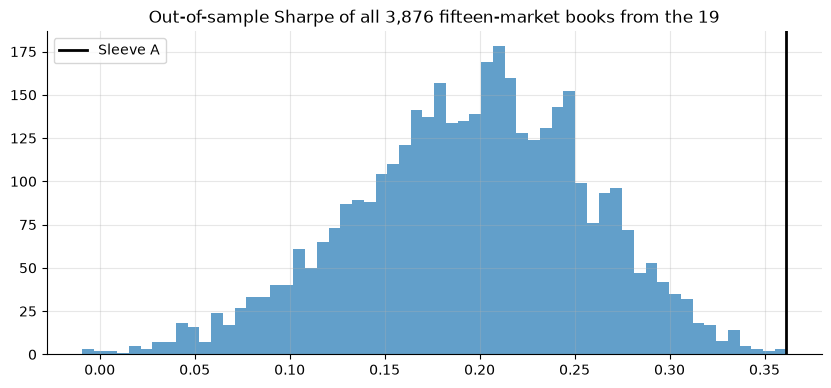

In [7]:
fig, ax = plt.subplots()
ax.hist(ex["oos"], bins=60, alpha=0.7)
ax.axvline(a15["oos"], color="k", lw=2, label="Sleeve A")
ax.set_title("Out-of-sample Sharpe of all 3,876 fifteen-market books from the 19")
ax.legend(); plt.show()

On today's engine Sleeve A is the single best of all 3,876. But it was
chosen using this same history, so a top rank is exactly what a selection
made on this data would show. A
rank on the selection sample is not evidence; section 6 is the real test.

## 4. What can actually be traded

Checked against every live symbol at the broker. The whole government bond
shelf is a dozen dated futures, and the only US Treasury is the 10-year.
These research markets have no tradeable instrument:

In [8]:
pd.Series({s: asset_class(s) for s in sorted(UNTRADEABLE)}, name="class").to_frame()

,class
australia10y,fixed_income
eurobobl,fixed_income
gilt,fixed_income
jgb,fixed_income
us2y,fixed_income
us5y,fixed_income
us_ultra,fixed_income


That list once lived as a copy in each notebook. One copy lacked the US
2-year, and a sleeve whose largest position was the US 2-year was reported
as tradeable. It now exists once, in `ctadata.universe.UNTRADEABLE`.

**Capital granularity** was checked too: at $100,000 the engine's sizes are
fractions of one standard exchange future for every market, so the live
book uses the broker's dated contracts and CFDs, which trade in 0.01 lots.
(That check also caught a unit error: some futures are quoted in cents, and
the yen future in cents per 100 yen.)

**A-12** is Sleeve A less the three markets in the list above: the US
2-year and the JGB (never offered) and the Gilt (listed, but every order
rejected server-side).

In [9]:
print("A-12:", A12)
describe({"Sleeve A, 15": ret(A15), "A-12": ret(A12)}, stacked=True)

A-12: ['aud', 'brent', 'copper', 'gbp', 'gold', 'jpy', 'nasdaq', 'nikkei', 'silver', 'spx', 'us10y', 'wti']


,sharpe,vol,cagr,max_dd,stacked_sharpe,stacked_cagr,stacked_max_dd
"Sleeve A, 15",0.3616,0.1361,0.0571,-0.2587,0.7251,0.1738,-0.3330
A-12,0.3428,0.1366,0.0544,-0.2507,0.7073,0.1703,-0.3210


## 5. A wider pool of 30, and a large random search

Five more markets (corn, coffee, orange juice, the DAX, the Hang Seng)
made a 30-market candidate pool. The original search drew 4.4 million
random 15-market books overnight and found books that beat Sleeve A by a
wide margin. A smaller draw shows the shape here.

In [10]:
P30 = sorted(df.columns)
rng = np.random.default_rng(0)
draws = [sorted(rng.choice(P30, 15, replace=False)) for _ in range(3000)]
mc = pd.DataFrame([dict(combo=",".join(d), oos=sh(ret(d)),
                        tradeable=not (set(d) & UNTRADEABLE)) for d in draws])
print(f"draws: {len(mc)}; tradeable: {int(mc.tradeable.sum())}")
print(f"best draw {mc.oos.max():.3f}; best tradeable draw {mc[mc.tradeable].oos.max():.3f}; "
      f"Sleeve A {sh(ret(A15)):.3f}")
top = mc.sort_values("oos", ascending=False).head(100)
freq = pd.Series([s for c in top.combo for s in c.split(",")]).value_counts() / len(top)
freq.head(12).rename("share of the top 100 draws").to_frame()

draws: 3000; tradeable: 16
best draw 0.474; best tradeable draw 0.361; Sleeve A 0.362


,share of the top 100 draws
nasdaq,0.9500
brent,0.8100
hangseng,0.7800
gold,0.7700
jpy,0.7100
wti,0.7100
spx,0.6900
canada10y,0.6600
nikkei,0.6300
australia10y,0.6300


The top of the search leans on markets that cannot be traded. More
importantly, "the best of thousands of draws, scored on the same data" is
the most extreme form of selecting on the sample.

## 6. The nested test: can the selection be made in advance?

The decisive test. Inside each two-year window, re-derive the selection
rule using ONLY the data before the window, then trade the selection on
the window, and chain the windows. Compared with simply holding the whole
pool.

Two rules: Sleeve A's mild one (cut the worst contributor in each class),
and an aggressive one (keep the top 15 by contribution, ignoring class).

In [11]:
P19 = E19
P17 = sorted(set(P19) - UNTRADEABLE)
POOL = sorted(set(df.columns) - UNTRADEABLE)
FOLDS = [("2010-09-04", "2012-09-04"), ("2012-09-04", "2014-09-04"), ("2014-09-04", "2016-09-04"),
         ("2016-09-04", "2018-09-04"), ("2018-09-04", "2020-09-04"), ("2020-09-04", "2022-09-04"),
         ("2022-09-04", "2024-09-04"), ("2024-09-04", "2026-09-28")]
TRAIN_FROM = "2007-11-26"          # the first day the bare engine is live


def contributions(pool, train_end):
    w = slice(TRAIN_FROM, train_end)
    base = sharpe(ret(pool).loc[w])
    return {s: base - sharpe(ret([x for x in pool if x != s]).loc[w]) for s in pool}


def mild_rule(pool, train_end):
    c = contributions(pool, train_end)
    keep = list(pool)
    for cls in sorted({asset_class(s) for s in pool}):
        members = [s for s in pool if asset_class(s) == cls]
        if len(members) >= 2:
            keep.remove(min(members, key=lambda s: c[s]))
    return sorted(keep)


def aggressive_rule(pool, train_end, k=15):
    c = contributions(pool, train_end)
    return sorted(sorted(pool, key=lambda s: -c[s])[:k])


chains = {k: [] for k in ("mild rule, re-derived", "aggressive rule, re-derived",
                          "hold the 17", "hold all tradeable", "A-12 held fixed")}
picks = []
for a, b in FOLDS:
    mild, aggr = mild_rule(P17, a), aggressive_rule(POOL, a)
    seg = {"mild rule, re-derived": ret(mild), "aggressive rule, re-derived": ret(aggr),
           "hold the 17": ret(P17), "hold all tradeable": ret(POOL), "A-12 held fixed": ret(A12)}
    for k, v in seg.items():
        chains[k].append(v.loc[a:b])
    picks.append(dict(window=a[:7], mild_overlap_with_A12=len(set(mild) & set(A12))))
res = {k: stats(pd.concat(v).pipe(lambda s: s[~s.index.duplicated()]), RF) for k, v in chains.items()}
pd.DataFrame(res).T

,sharpe,vol,cagr,max_dd
"mild rule, re-derived",0.2306,0.1330,0.0391,-0.2763
"aggressive rule, re-derived",0.1488,0.1329,0.0275,-0.3161
hold the 17,0.2611,0.1357,0.0438,-0.2733
hold all tradeable,0.2569,0.1353,0.0431,-0.2770
A-12 held fixed,0.4173,0.1366,0.0671,-0.2507


In [12]:
pd.DataFrame(picks).set_index("window").T

window,2010-09,2012-09,2014-09,2016-09,2018-09,2020-09,2022-09,2024-09
mild_overlap_with_A12,8,8,8,8,11,12,11,12


**Aggressive selection, made in advance, does worse than not selecting at
all.** The books built from the full-sample search (and the 4.4-million
draw winner) only look good because they were scored on the data that
chose them. All of them were dropped.

The mild rule keeps rediscovering almost the same markets as A-12, more so
in later folds. But re-derived without hindsight it is worth much less than A-12
held fixed, and it does not beat simply holding the pool either.

That last point corrects the project's own history. An earlier run of
this test had the mild rule ahead of the pool (0.42 against 0.38), and that
result is why the A-13 universe was adopted. A later, fuller run (the one
reproduced here) does not support it: the project's own records show the
rule at 0.357 against 0.381 for the pool, consistent with the table above. A-12 is still the right
LIVE universe for other reasons (it is what the broker can trade, and the
wide pool fails for a specific reason, Chapter 8), but not because
selection was shown to add value. The gap between A-12 fixed and the rule
re-derived is the next section.

## 7. The selection premium

A-12 held fixed over these windows is not a fair number: A-12 was chosen
using all of them. The fair number for "this way of choosing markets" is
the rule re-derived per window. The difference is the **selection
premium** carried by every headline quoted for A-12.

In [13]:
prem = res["A-12 held fixed"]["sharpe"] - res["mild rule, re-derived"]["sharpe"]
print(f"A-12 held fixed      {res['A-12 held fixed']['sharpe']:+.3f}")
print(f"the rule, re-derived {res['mild rule, re-derived']['sharpe']:+.3f}")
print(f"selection premium    {prem:+.3f}")

A-12 held fixed      +0.417
the rule, re-derived +0.231
selection premium    +0.187


The original measurement, on the same principle, was 0.185. The live
expectation for the strategy was set accordingly: a Sharpe nearer 0.35 to
0.40 than the headline, and the live demo is the only genuinely clean
out-of-sample window the strategy will ever get.

## What this chapter established

* More markets help only when they add independent bets.
* Choosing markets on past performance looks excellent and is mostly
  self-deception; tested out of sample, aggressive selection loses to holding
  the pool.
* Even the mild, class-balanced rule does not beat holding the pool when
  re-derived without hindsight. A-12 is the live universe because the broker can
  trade it and the wide pool fails for a diagnosable reason (Chapter 8);
  its headline is discounted by the measured selection premium.